# TremorLens: Exploratory Data Analysis (Part 2)

Part 1 covered data quality, depth, the Gutenberg-Richter law and time patterns.
This part covers **maps**, a **Pakistan and Hindu Kush** focus, and the **USGS against EMSC** comparison for matched events.
The notebook is self-contained: it loads its own data, so it can be run on its own.

**Sections:** 9 world maps, 10 Pakistan and region, 11 USGS against EMSC, 12 summary of findings.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
engine = create_engine(os.environ["DATABASE_URL"])

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DEFAULT_DEPTHS = [10, 30, 33, 35]   # depths that are far more common than their neighbours (see Part 1, section 3b)


def q(sql):
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

In [2]:
usgs = q("""SELECT event_id, event_time, latitude, longitude, depth_km, magnitude, mag_type, place
                FROM usgs_events""")
usgs["event_time"] = pd.to_datetime(usgs["event_time"], utc=True)
usgs["year"] = usgs["event_time"].dt.year
usgs["depth_is_default_any"] = usgs["depth_km"].isin(DEFAULT_DEPTHS)

pairs = q("""SELECT c.event_id, c.event_time,
                     u.magnitude AS mag_usgs, e.magnitude AS mag_emsc,
                     u.depth_km AS depth_usgs, e.depth_km AS depth_emsc,
                     u.mag_type AS type_usgs, e.mag_type AS type_emsc
              FROM events_clean c
              JOIN usgs_events u ON u.event_id = c.matched_usgs_id
              JOIN emsc_events e ON e.event_id = c.matched_emsc_id
              WHERE c.source = 'both'""")
pairs["event_time"] = pd.to_datetime(pairs["event_time"], utc=True)
pairs["year"] = pairs["event_time"].dt.year

print(f"USGS events : {len(usgs):,}")
print(f"matched pairs: {len(pairs):,}")

USGS events : 187,980
matched pairs: 109,305


## 9. World maps

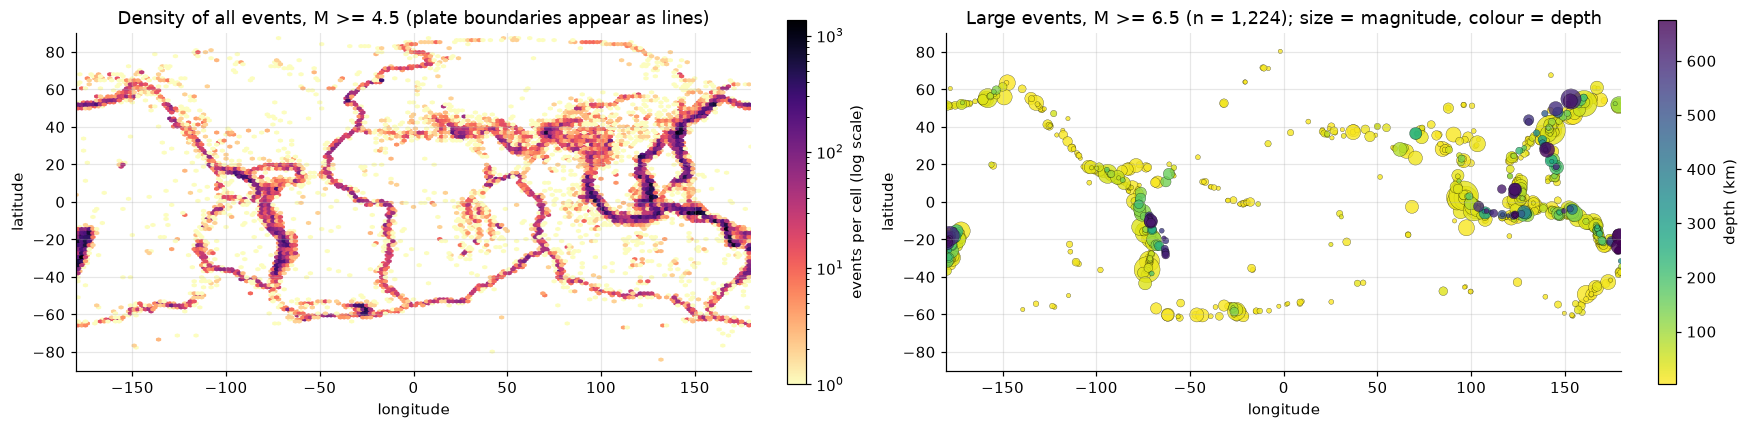

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

hb = ax[0].hexbin(usgs["longitude"], usgs["latitude"], gridsize=(180, 80), bins="log", mincnt=1, cmap="magma_r")
fig.colorbar(hb, ax=ax[0], fraction=0.025, label="events per cell (log scale)")
ax[0].set_title("Density of all events, M >= 4.5 (plate boundaries appear as lines)")

big = usgs[usgs["magnitude"] >= 6.5].sort_values("depth_km")
sc = ax[1].scatter(big["longitude"], big["latitude"], c=big["depth_km"].clip(0, 700),
                   s=np.clip((big["magnitude"] - 5.5) ** 3 * 8, 6, None), cmap="viridis_r",
                   alpha=0.8, edgecolor="k", linewidth=0.2)
fig.colorbar(sc, ax=ax[1], fraction=0.025, label="depth (km)")
ax[1].set_title(f"Large events, M >= 6.5 (n = {len(big):,}); size = magnitude, colour = depth")

for a in ax:
    a.set_xlim(-180, 180); a.set_ylim(-90, 90)
    a.set_xlabel("longitude"); a.set_ylabel("latitude"); a.set_aspect("equal")
save("09_world_maps")

**What to look for:** the density map should draw the plate boundaries: the Pacific Ring of Fire, the Mid-Atlantic and other ridges, and the Alpine-Himalayan belt that crosses Pakistan.
Deep events (dark colours in the right panel) should sit along subduction zones, not along ridges.
Write 2 or 3 lines about what you see.

## 10. Pakistan and region

In [4]:
REGIONS = {
    "Pakistan and region": dict(lat=(23, 38), lon=(60, 78)),
    "Hindu Kush cluster": dict(lat=(35, 37.5), lon=(69, 72)),
}


def in_box(df, box):
    return df[df["latitude"].between(*box["lat"]) & df["longitude"].between(*box["lon"])]


rows = []
subsets = {}
for name, box in REGIONS.items():
    sub = in_box(usgs, box)
    subsets[name] = sub
    known = sub.loc[~sub["depth_is_default_any"] & (sub["depth_km"] >= 0), "depth_km"]
    rows.append({
        "region": name,
        "events": len(sub),
        "share of world": f"{len(sub) / len(usgs):.2%}",
        "M >= 6": int((sub["magnitude"] >= 6).sum()),
        "median depth, known (km)": round(known.median(), 1) if len(known) else np.nan,
        "share with default-like depth": f"{sub['depth_is_default_any'].mean():.1%}",
    })
display(pd.DataFrame(rows))

pk = subsets["Pakistan and region"]
hk = subsets["Hindu Kush cluster"]
print("Boxes (latitude, longitude):", {k: (v["lat"], v["lon"]) for k, v in REGIONS.items()})
print("The Pakistan box also contains parts of Afghanistan, India, Iran, Tajikistan and China; it is a region, not a border.")

,region,events,share of world,M >= 6,"median depth, known (km)",share with default-like depth
0,Pakistan and region,2518,1.34%,49,107.3,33.4%
1,Hindu Kush cluster,1158,0.62%,27,136.2,6.6%


Boxes (latitude, longitude): {'Pakistan and region': ((23, 38), (60, 78)), 'Hindu Kush cluster': ((35, 37.5), (69, 72))}
The Pakistan box also contains parts of Afghanistan, India, Iran, Tajikistan and China; it is a region, not a border.


In [5]:
top = pk.nlargest(10, "magnitude")[["event_time", "magnitude", "depth_km", "place"]].copy()
top["event_time"] = top["event_time"].dt.strftime("%Y-%m-%d %H:%M")
display(top.reset_index(drop=True))

,event_time,magnitude,depth_km,place
0,2001-01-26 03:16,7.7,16.0,"17 km NW of Bhach?u, India"
1,2013-04-16 10:44,7.7,80.0,"79 km ESE of Kh?sh, Iran"
2,2013-09-24 11:29,7.7,15.0,"113 km NW of Bela, Pakistan"
3,2005-10-08 03:50,7.6,26.0,"21 km NNE of Muzaffar?b?d, Pakistan"
4,2015-10-26 09:09,7.5,231.0,"Hindu Kush region, Afghanistan"
5,2002-03-03 12:08,7.4,225.6,"51 km SW of Jurm, Afghanistan"
6,2011-01-18 20:23,7.2,68.0,"46 km WSW of Dalbandin, Pakistan"
7,2013-09-28 07:34,6.8,12.0,"129 km WSW of Khuzdar, Pakistan"
8,2004-04-05 21:24,6.6,187.1,Afghanistan-Tajikistan-Pakistan region
9,2009-01-03 20:23,6.6,204.8,"50 km S of Jurm, Afghanistan"


**Check against reality:** the list above should contain well-known earthquakes of the region (for example the October 2005 Kashmir earthquake and the 2015 Hindu Kush earthquake).
If a well-known event is missing, that is a data problem worth reporting.

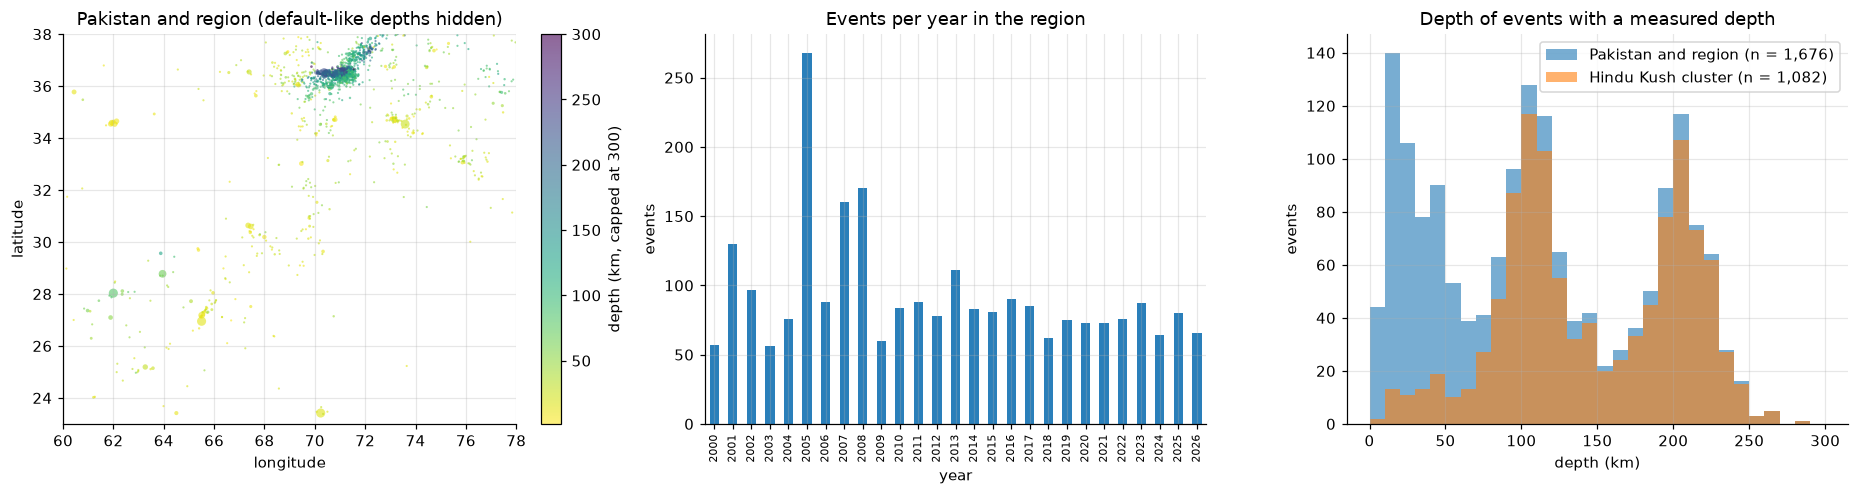

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

# (a) map of the region, known depths only
known = pk[~pk["depth_is_default_any"]]
sc = ax[0].scatter(known["longitude"], known["latitude"], c=known["depth_km"].clip(0, 300),
                   s=np.clip((known["magnitude"] - 4.0) ** 2.2 * 2, 2, None), cmap="viridis_r", alpha=0.6, linewidth=0)
fig.colorbar(sc, ax=ax[0], fraction=0.046, label="depth (km, capped at 300)")
ax[0].set_xlim(*REGIONS["Pakistan and region"]["lon"]); ax[0].set_ylim(*REGIONS["Pakistan and region"]["lat"])
ax[0].set_title("Pakistan and region (default-like depths hidden)")
ax[0].set_xlabel("longitude"); ax[0].set_ylabel("latitude")

# (b) events per year
pk.groupby("year").size().plot.bar(ax=ax[1], color="#2a7fba")
ax[1].set_title("Events per year in the region")
ax[1].set_xlabel("year"); ax[1].set_ylabel("events")
ax[1].tick_params(axis="x", labelsize=7)

# (c) depth of known events, region against Hindu Kush box
bins = np.arange(0, 301, 10)
for name, sub in subsets.items():
    d = sub.loc[~sub["depth_is_default_any"] & (sub["depth_km"] >= 0), "depth_km"]
    ax[2].hist(d, bins=bins, alpha=0.6, label=f"{name} (n = {len(d):,})")
ax[2].set_title("Depth of events with a measured depth")
ax[2].set_xlabel("depth (km)"); ax[2].set_ylabel("events"); ax[2].legend()
save("10_pakistan_region")

**Result:** the Hindu Kush cluster has intermediate-depth earthquakes with two depth peaks, at about 100 to 120 km and about 200 to 220 km (median measured depth 136 km), while the wider region also has a shallow group at 10 to 50 km. Only 6.6 percent of the Hindu Kush events have a default-like depth, against 33.4 percent for the whole region. The year with the most events is 2005, the year of the Kashmir earthquake.

In [7]:
bands = pd.cut(usgs["magnitude"], [0, 5.0, 6.0, 7.0, 20], right=False, labels=["4.5-4.9", "5.0-5.9", "6.0-6.9", "7.0+"])
world = bands.value_counts(normalize=True).sort_index()
region = pd.cut(pk["magnitude"], [0, 5.0, 6.0, 7.0, 20], right=False,
                labels=["4.5-4.9", "5.0-5.9", "6.0-6.9", "7.0+"]).value_counts(normalize=True).sort_index()
cmp = pd.DataFrame({"world": world, "Pakistan and region": region})
display(cmp.style.format("{:.1%}"))

,world,Pakistan and region
magnitude,,
4.5-4.9,74.4%,79.7%
5.0-5.9,23.5%,18.4%
6.0-6.9,1.9%,1.7%
7.0+,0.2%,0.3%


## 11. USGS against EMSC for matched events

Only events that both catalogs contain (about 109,000 pairs) are used here.

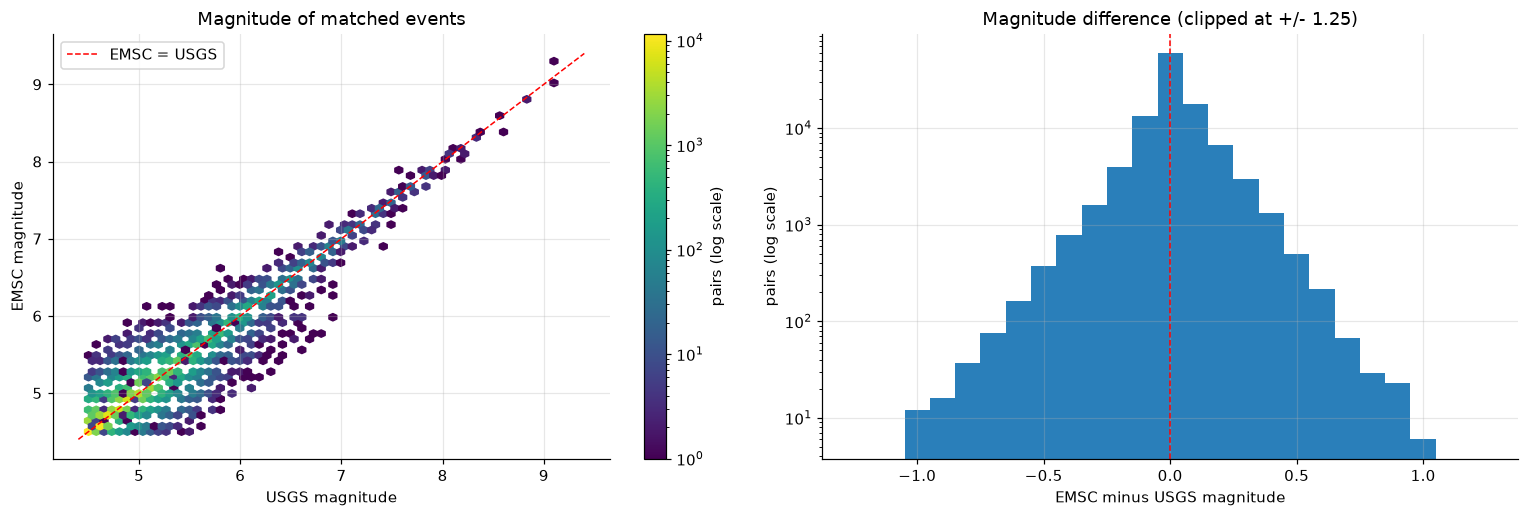

,mean,median,std,share within 0.1,share within 0.3
EMSC minus USGS,0.016,0.0,0.134,0.827,0.967


In [8]:
pairs["dmag"] = pairs["mag_emsc"] - pairs["mag_usgs"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
hb = ax[0].hexbin(pairs["mag_usgs"], pairs["mag_emsc"], gridsize=60, bins="log", mincnt=1, cmap="viridis")
fig.colorbar(hb, ax=ax[0], label="pairs (log scale)")
lim = [4.4, max(pairs["mag_usgs"].max(), pairs["mag_emsc"].max()) + 0.1]
ax[0].plot(lim, lim, "r--", lw=1, label="EMSC = USGS")
ax[0].set_xlabel("USGS magnitude"); ax[0].set_ylabel("EMSC magnitude")
ax[0].set_title("Magnitude of matched events"); ax[0].legend()

ax[1].hist(pairs["dmag"].clip(-1.25, 1.25), bins=np.arange(-1.25, 1.3, 0.1), color="#2a7fba")
ax[1].set_yscale("log")
ax[1].axvline(0, color="r", ls="--", lw=1)
ax[1].set_xlabel("EMSC minus USGS magnitude"); ax[1].set_ylabel("pairs (log scale)")
ax[1].set_title("Magnitude difference (clipped at +/- 1.25)")
save("11_magnitude_comparison")

stats = pd.DataFrame({
    "mean": [pairs["dmag"].mean()], "median": [pairs["dmag"].median()], "std": [pairs["dmag"].std()],
    "share within 0.1": [(pairs["dmag"].abs() <= 0.1001).mean()],
    "share within 0.3": [(pairs["dmag"].abs() <= 0.3001).mean()],
}, index=["EMSC minus USGS"])
display(stats.round(3))

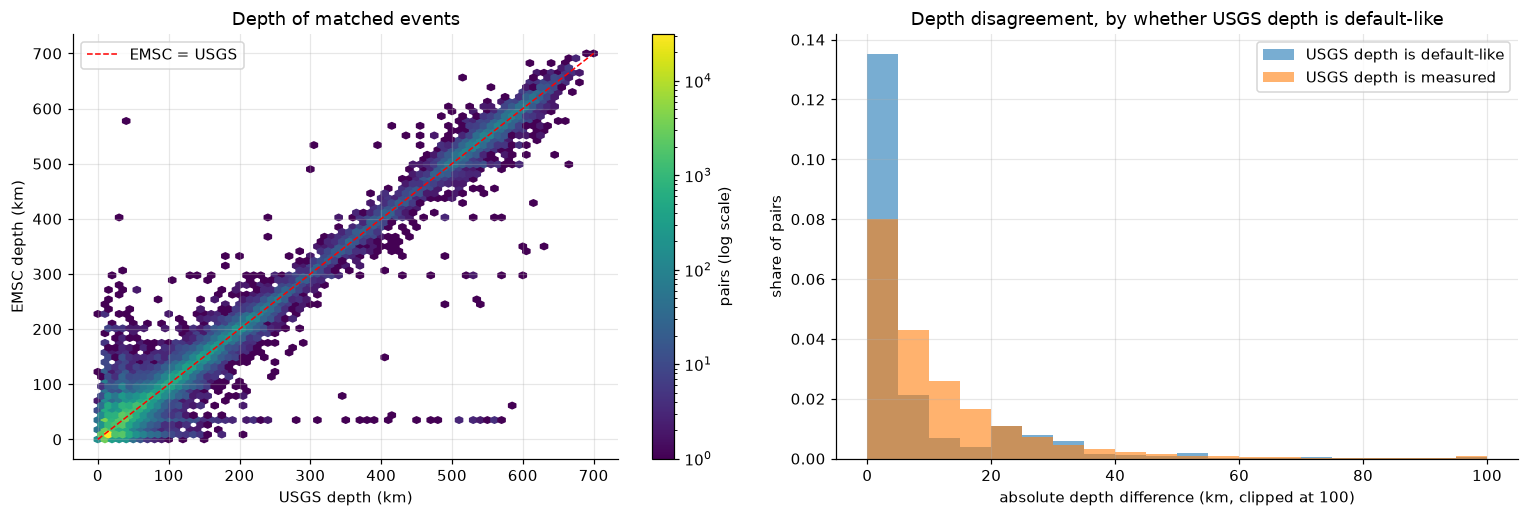

,pairs,median,mean,share_over_100km
USGS depth measured,64463,7.0,11.650,0.004
USGS depth default-like,44842,0.0,7.022,0.003


In [9]:
dp = pairs.dropna(subset=["depth_usgs", "depth_emsc"]).copy()
dp["ddepth"] = (dp["depth_emsc"] - dp["depth_usgs"]).abs()
dp["usgs_default"] = dp["depth_usgs"].isin(DEFAULT_DEPTHS)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
hb = ax[0].hexbin(dp["depth_usgs"].clip(0, 700), dp["depth_emsc"].clip(0, 700), gridsize=70, bins="log", mincnt=1, cmap="viridis")
fig.colorbar(hb, ax=ax[0], label="pairs (log scale)")
ax[0].plot([0, 700], [0, 700], "r--", lw=1, label="EMSC = USGS")
ax[0].set_xlabel("USGS depth (km)"); ax[0].set_ylabel("EMSC depth (km)")
ax[0].set_title("Depth of matched events"); ax[0].legend()

for flag, lab in [(True, "USGS depth is default-like"), (False, "USGS depth is measured")]:
    ax[1].hist(dp.loc[dp["usgs_default"] == flag, "ddepth"].clip(0, 100), bins=np.arange(0, 101, 5), alpha=0.6, label=lab, density=True)
ax[1].set_xlabel("absolute depth difference (km, clipped at 100)"); ax[1].set_ylabel("share of pairs")
ax[1].set_title("Depth disagreement, by whether USGS depth is default-like"); ax[1].legend()
save("11_depth_comparison")

summary = dp.groupby("usgs_default")["ddepth"].agg(pairs="size", median="median", mean="mean",
                                                    share_over_100km=lambda s: (s > 100).mean())
summary.index = ["USGS depth measured" if not i else "USGS depth default-like" for i in summary.index]
display(summary.round(3))

**Result:** points lie close to the red line, so the catalogs agree on depth in general. One exception is a horizontal band where EMSC reports about 33 to 35 km for events that USGS places at 250 to 600 km: EMSC also uses default depths. The agreement is better, not worse, when the USGS depth is default-like (median difference 0.0 km against 7.0 km), most likely because EMSC repeats the USGS (NEIC) depth including its default value. So agreement between two default values is not evidence that the depth is correct. Only 0.4 and 0.3 percent of the pairs differ by more than 100 km.

## 12. Summary of findings

1. **Where earthquakes happen:** the density map of 187,980 events draws the plate boundaries (Pacific Ring of Fire, mid-ocean ridges, Alpine-Himalayan belt). The deepest large events (500 to 700 km) lie along subduction zones.
2. **Pakistan and Hindu Kush:** 2,518 events in the region (1.34 percent of the world), 49 of magnitude 6 or more. Its largest events are well known (Bhuj 2001, Balochistan 2013, Kashmir 2005, Hindu Kush 2015). The Hindu Kush cluster (1,158 events) has intermediate depths with peaks at about 100 to 120 km and 200 to 220 km.
3. **Agreement of the catalogs:** for 109,305 matched events the magnitude difference (EMSC minus USGS) has mean +0.016, median 0.0 and standard deviation 0.134. 82.7 percent of the pairs differ by at most 0.1 and 96.7 percent by at most 0.3.
4. **Depth reliability:** both catalogs use default depths, and when USGS uses one, EMSC usually repeats it (median difference 0.0 km), so agreement does not prove that the depth is right. Only 0.3 to 0.4 percent of the pairs differ by more than 100 km.
5. **Consequences for later work:** USGS is the base catalog, the modelling window is 2005 to 2026, a default-depth flag is added as a feature, and `felt`, `cdi`, `mmi` and `sig` are never used as features.